In [8]:
import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

P = '/content/'
day  = pd.read_csv(P + 'city_day_clean.csv', parse_dates=['Date'])
hour = pd.read_csv(P + 'city_hour_clean.csv')
day['City'] = day['City'].str.strip()
hour['City'] = hour['City'].str.strip()

print(day.shape, hour.shape)
print(day.columns.tolist())
print(hour.columns.tolist())

(24801, 23) (650264, 29)
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'Day', 'Weekday', 'Is_Weekend', 'Season', 'Is_Winter', 'Is_Diwali_Period']
['City', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket', 'Hour', 'Month', 'Year', 'Weekday', 'is_winter', 'is_weekend', 'is_rush_hour', 'is_night', 'hour_sin', 'hour_cos', 'season_Monsoon', 'season_PostMonsoon', 'season_Summer', 'season_Winter']


In [9]:
dt_col = next(c for c in hour.columns if 'date' in c.lower())
hour[dt_col] = pd.to_datetime(hour[dt_col], errors='coerce')
hour['Date'] = hour[dt_col].dt.normalize()

keep = [c for c in ['PM2.5','PM10','NO2','CO','O3'] if c in hour.columns]
d = hour.groupby(['City','Date'])[keep].agg(['max','std'])
d.columns = [f'{a}_{b}' for a,b in d.columns]
d = d.reset_index()
HOUR_FEATS = [c for c in d.columns if c not in ('City','Date')]

df = day.merge(d, on=['City','Date'], how='left')
df['has_hourly'] = df[HOUR_FEATS[0]].notna().astype(int)

print(df.shape, '| rows with hourly match:', df['has_hourly'].sum())
print('cities with hourly data:', df.loc[df.has_hourly==1,'City'].nunique(), 'of', df.City.nunique())

(24801, 34) | rows with hourly match: 24172
cities with hourly data: 26 of 26


In [10]:
POLL = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene']
diw = [c for c in df.columns if 'diwali' in c.lower()]
DIWALI = diw[0] if diw else None

# 1. full calendar per city, so a shift is always exactly one day
parts = []
for city, g in df.sort_values('Date').groupby('City'):
    g = g.set_index('Date')
    g = g.reindex(pd.date_range(g.index.min(), g.index.max(), freq='D'))
    g['City'] = city
    parts.append(g.rename_axis('Date').reset_index())
full = pd.concat(parts, ignore_index=True).sort_values(['City','Date'])

g = full.groupby('City')['AQI']
full['AQI_next']  = g.shift(-1)                      # TARGET
full['AQI_today'] = full['AQI']
full['AQI_lag1']  = g.shift(1)
full['AQI_lag2']  = g.shift(2)
full['AQI_roll3'] = g.transform(lambda s: s.rolling(3, min_periods=2).mean())
full['AQI_roll7'] = g.transform(lambda s: s.rolling(7, min_periods=4).mean())
full['AQI_diff']  = full['AQI_today'] - full['AQI_lag1']

# 2. calendar features of TOMORROW as known in advance
nxt = full['Date'] + pd.Timedelta(days=1)
full['month_next']   = nxt.dt.month
full['weekday_next'] = nxt.dt.weekday
full['weekend_next'] = (full['weekday_next'] >= 5).astype(int)
full['winter_next']  = full['month_next'].isin([12,1,2]).astype(int)
full['season_next']  = full['month_next'].map(lambda m: 'Winter' if m in (12,1,2) else
                        'Summer' if m in (3,4,5) else 'Monsoon' if m in (6,7,8,9) else 'PostMonsoon')
if DIWALI:
    full['diwali_next'] = full.groupby('City')[DIWALI].shift(-1).fillna(0)

# 3. we keep only real rows where today's and tomorrow's AQI both exist
data = full.dropna(subset=['AQI_today','AQI_next']).copy()
data['target_date'] = data['Date'] + pd.Timedelta(days=1)

train = data[data['target_date'] <  '2019-01-01'].copy()
test  = data[data['target_date'] >= '2019-01-01'].copy()
print(len(train), len(test))

12991 11300


In [7]:
LAGS  = ['AQI_today','AQI_lag1','AQI_lag2','AQI_roll3','AQI_roll7','AQI_diff']
TODAY = POLL                       # today's pollutant readings
FILL  = LAGS + POLL + HOUR_FEATS

city_med = train.groupby('City')[FILL].median()
glob_med = train[FILL].median()
def fill(part):
    part = part.copy()
    m = part[['City']].join(city_med, on='City')
    for c in FILL:
        part[c] = part[c].fillna(m[c]).fillna(glob_med[c])
    return part
train, test = fill(train), fill(test)

CAL = ['month_next','weekday_next','weekend_next','winter_next'] + (['diwali_next'] if DIWALI else [])

def X_of(part, feats):
    X = part[feats + CAL].copy()
    return pd.concat([X, pd.get_dummies(part['season_next'], prefix='season'),
                         pd.get_dummies(part['City'], prefix='city')], axis=1)

FEATURE_SETS = {
  'N1: AQI history only':               LAGS,
  'N2: + today pollutants':             LAGS + TODAY,
  'N3: + today pollutants + hourly':    LAGS + TODAY + HOUR_FEATS + ['has_hourly'],
}

In [5]:
def score(y, p, name):
    return {'Model': name,
            'MAE':  round(mean_absolute_error(y, p), 1),
            'RMSE': round(mean_squared_error(y, p) ** 0.5, 1),
            'R2':   round(r2_score(y, p), 3)}

y_te = test['AQI_next']
rows = [score(y_te, [train['AQI_next'].mean()] * len(test), 'Baseline: training mean'),
        score(y_te, test['AQI_today'],                        'Baseline: persistence (tomorrow = today)')]

preds = {}
for name, feats in FEATURE_SETS.items():
    Xtr = X_of(train, feats)
    Xte = X_of(test, feats).reindex(columns=Xtr.columns, fill_value=0)
    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(Xtr, train['AQI_next'])
    preds[name] = (rf, Xtr.columns, rf.predict(Xte))
    rows.append(score(y_te, preds[name][2], name))

results = pd.DataFrame(rows)
display(results)

,Model,MAE,RMSE,R2
0,Baseline: training mean,102.3,129.6,-0.171
1,Baseline: persistence (tomorrow = today),26.4,60.4,0.746
2,N1: AQI history only,27.5,58.3,0.763
3,N2: + today pollutants,22.5,47.9,0.840
4,N3: + today pollutants + hourly,21.2,44.8,0.860


Best model: N3: + today pollutants + hourly
City
Bengaluru              8.1
Hyderabad              8.5
Coimbatore             8.6
Thiruvananthapuram     9.4
Ernakulam             10.1
Aizawl                10.9
Mumbai                11.7
Shillong              12.0
Kochi                 13.3
Amaravati             13.3
Jaipur                14.8
Chandigarh            15.3
Visakhapatnam         16.1
Chennai               16.3
Bhopal                16.7
Kolkata               18.3
Brajrajnagar          20.2
Amritsar              21.1
Talcher               22.4
Patna                 22.6
Jorapokhar            23.1
Lucknow               24.9
Gurugram              26.9
Delhi                 27.0
Guwahati              28.3
Ahmedabad             97.4
Name: err, dtype: float64


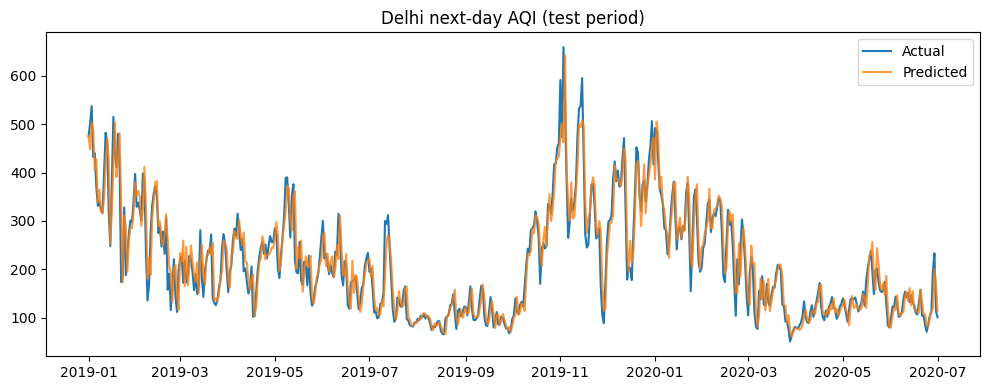

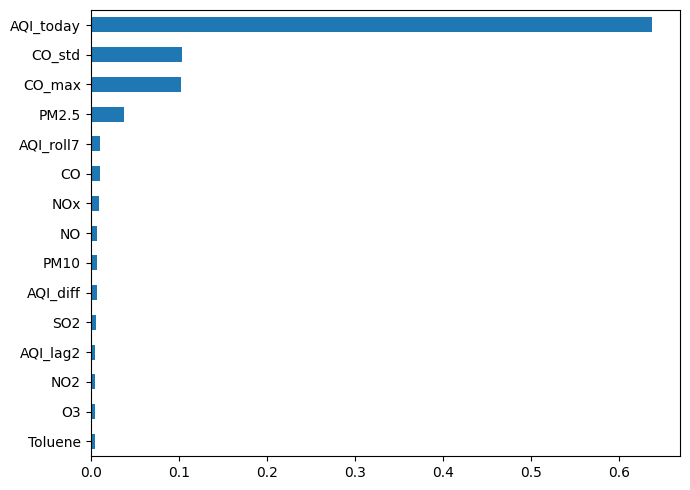

In [6]:
import matplotlib.pyplot as plt

best = results.iloc[2:].sort_values('MAE').iloc[0]['Model']
rf, cols, p = preds[best]
print('Best model:', best)

# error by city
by_city = (pd.DataFrame({'City': test['City'].values, 'err': abs(y_te.values - p)})
           .groupby('City')['err'].mean().round(1).sort_values())
print(by_city)

# Delhi: actual vs predicted
m = (test['City'] == 'Delhi').values
plt.figure(figsize=(10,4))
plt.plot(test.loc[m,'target_date'], y_te[m], label='Actual')
plt.plot(test.loc[m,'target_date'], p[m], label='Predicted', alpha=.8)
plt.title('Delhi next-day AQI (test period)'); plt.legend(); plt.tight_layout()
plt.savefig('/content/model_a_nextday_delhi.png', dpi=150); plt.show()

pd.Series(rf.feature_importances_, index=cols).sort_values().tail(15).plot.barh(figsize=(7,5))
plt.tight_layout(); plt.savefig('/content/model_a_nextday_importance.png', dpi=150); plt.show()

results.to_csv('/content/model_a_nextday_results.csv', index=False)